# Seyirci Gerçekten Maç Kazandırır mı? NBA Bubble ve Ev Sahibi Avantajı

**Araştırma sorusu:** NBA'de ev sahibi avantajının ne kadarı seyirciden geliyor? 2020 NBA Bubble'ı (maçların seyircisiz ve tarafsız sahada oynandığı dönem, 30 Temmuz – 11 Ekim 2020) bu soru için bir *natural experiment* (doğal deney) sunuyor.

**Veri:** Kaggle – *NBA games data* (nathanlauga), `games.csv`. Ekim 2003 – Aralık 2022 arası 26.651 maç; her satır bir maç, hedef değişken `HOME_TEAM_WINS`.

**Yöntem:**
1. Veri temizliği ve tip optimizasyonu
2. EDA: sezonlara göre ev sahibi kazanma oranı ve sayı farkı, güven aralıkları
3. Hipotez testi: 2019-20 sezonundaki düşüş COVID'le mi ilgili?
4. Model: maç öncesi bilgilerle (takım formu, dinlenme) Logistic Regression; seyircisiz dönemin etkisini takım gücünü kontrol ederek ölçmek

---
## 1. Veri yükleme ve tip optimizasyonu

- `GAME_STATUS_TEXT` sütunu tek bir değer içeriyor (`"Final"`), bilgi taşımadığı için çıkarıldı.
- PCT (yüzde) sütunları kontrol edildi: değerler 0–1 aralığında, veri sağlam. (Dosya Türkçe ayarlı Excel'de açıldığında `0.913` → `913` görünüyor; bu Excel'in ondalık ayırıcı sorunu, veride bir hata yok. Ham veri her zaman pandas ile incelenmeli.)
- Hedef değişken `HOME_TEAM_WINS` 0/1'den `bool`'a çevrildi (1 byte).
- *Downcasting* (veri tipini küçültme): ID'ler `int32`, yüzdeler `float32`, sayaçlar `Int16` (büyük I = NaN'a izin veren *nullable* tip).
- **Sonuç: bellek kullanımı 5.7 MB → 1.95 MB (yaklaşık %66 azalma).**

In [1]:
   %pip install pandas numpy matplotlib scikit-learn statsmodels

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 25.0.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [2]:
import pandas as pd

# 1) Yükle
games = pd.read_csv("D:\\Indirilenler56\\nbaa_bubble\\games.csv~1\\games.csv", parse_dates=["GAME_DATE_EST"])
print("Önce:", round(games.memory_usage(deep=True).sum() / 1e6, 2), "MB")

# 2) Gereksiz sütun: tek değer içeriyor ("Final"), bilgi taşımıyor
print(games["GAME_STATUS_TEXT"].unique())
games = games.drop(columns=["GAME_STATUS_TEXT"])

# 3) PCT sütunları: önce kontrol et, gerekirse düzelt
pct_cols = [c for c in games.columns if "PCT" in c]
print(games[pct_cols].describe().loc[["min", "max"]])  # 0-1 arasındaysa sorun yok

for col in pct_cols:
    if games[col].max() > 1:  # sadece gerçekten bozuksa düzelt
        games[col] = games[col] / 1000
    games[col] = games[col].astype("float32")  # float64 -> float32, yarı yer

# 4) Hedef değişken: 0/1 -> bool (1 byte)
games["HOME_TEAM_WINS"] = games["HOME_TEAM_WINS"].astype(bool)

# 5) Diğer sayısal sütunları küçült
id_cols = [c for c in games.columns if "ID" in c]
games[id_cols] = games[id_cols].astype("int32")
games["SEASON"] = games["SEASON"].astype("int16")

count_cols = [c for c in games.columns if c.startswith(("PTS", "AST", "REB"))]
games[count_cols] = games[count_cols].astype("Int16")  # büyük I: NaN'a izin verir

print("Sonra:", round(games.memory_usage(deep=True).sum() / 1e6, 2), "MB")
print(games.dtypes)

Önce: 5.7 MB
<StringArray>
['Final']
Length: 1, dtype: str
     FG_PCT_home  FT_PCT_home  FG3_PCT_home  FG_PCT_away  FT_PCT_away  \
min        0.250        0.143           0.0        0.244        0.143   
max        0.684        1.000           1.0        0.687        1.000   

     FG3_PCT_away  
min           0.0  
max           1.0  
Sonra: 1.95 MB
GAME_DATE_EST      datetime64[us]
GAME_ID                     int32
HOME_TEAM_ID                int32
VISITOR_TEAM_ID             int32
SEASON                      int16
TEAM_ID_home                int32
PTS_home                    Int16
FG_PCT_home               float32
FT_PCT_home               float32
FG3_PCT_home              float32
AST_home                    Int16
REB_home                    Int16
TEAM_ID_away                int32
PTS_away                    Int16
FG_PCT_away               float32
FT_PCT_away               float32
FG3_PCT_away              float32
AST_away                    Int16
REB_away                    Int16


## 2. İlk bakış

**Not:** `PTS_home` sayısı 26.552, toplam satır 26.651 → **99 maçta istatistikler eksik (NaN).** Skoru olmayan bu maçlar sayı farkı (margin) hesaplarında otomatik olarak dışarıda kalıyor.

In [3]:
games.describe()

,GAME_DATE_EST,GAME_ID,HOME_TEAM_ID,VISITOR_TEAM_ID,SEASON,TEAM_ID_home,PTS_home,FG_PCT_home,FT_PCT_home,FG3_PCT_home,AST_home,REB_home,TEAM_ID_away,PTS_away,FG_PCT_away,FT_PCT_away,FG3_PCT_away,AST_away,REB_away
count,26651,2.665100e+04,2.665100e+04,2.665100e+04,26651.000000,2.665100e+04,26552.0,26552.000000,26552.000000,26552.000000,26552.0,26552.0,2.665100e+04,26552.0,26552.000000,26552.000000,26552.000000,26552.0,26552.0
mean,2013-03-05 02:57:13.447150,2.175487e+07,1.610613e+09,1.610613e+09,2012.113879,1.610613e+09,103.455898,0.460735,0.760377,0.356023,22.823441,43.374284,1.610613e+09,100.639876,0.449732,0.758816,0.349489,21.496271,42.113249
min,2003-10-05 00:00:00,1.030000e+07,1.610613e+09,1.610613e+09,2003.000000,1.610613e+09,36.0,0.250000,0.143000,0.000000,6.0,15.0,1.610613e+09,33.0,0.244000,0.143000,0.000000,4.0,19.0
25%,2008-03-14 00:00:00,2.070001e+07,1.610613e+09,1.610613e+09,2007.000000,1.610613e+09,94.0,0.422000,0.697000,0.286000,19.0,39.0,1.610613e+09,91.0,0.412000,0.692000,0.278000,18.0,38.0
50%,2013-02-24 00:00:00,2.120076e+07,1.610613e+09,1.610613e+09,2012.000000,1.610613e+09,103.0,0.460000,0.765000,0.357000,23.0,43.0,1.610613e+09,100.0,0.449000,0.765000,0.350000,21.0,42.0
75%,2017-12-18 00:00:00,2.180005e+07,1.610613e+09,1.610613e+09,2017.000000,1.610613e+09,112.0,0.500000,0.833000,0.429000,26.0,48.0,1.610613e+09,110.0,0.487000,0.833000,0.419000,25.0,46.0
max,2022-12-22 00:00:00,5.210021e+07,1.610613e+09,1.610613e+09,2022.000000,1.610613e+09,168.0,0.684000,1.000000,1.000000,50.0,72.0,1.610613e+09,168.0,0.687000,1.000000,1.000000,46.0,81.0
std,NaN,5.570189e+06,8.638670e+00,8.659299e+00,5.587031,8.638670e+00,13.28337,0.056676,0.100677,0.111164,5.193308,6.625769,8.659299e+00,13.435868,0.055551,0.103429,0.109441,5.160596,6.533039


## 3. Tekrar eden kayıt kontrolü

`GAME_ID`'ye göre **29 tekrar** var. Bir sonraki adımda inceleniyor.

In [4]:
games["GAME_ID"].duplicated().sum()

np.int64(29)

## 4. Temizlik, maç türü ve Bubble bayrağı

- **27 birebir aynı satır** silindi.
- `GAME_ID`'nin ilk hanesi maç türünü gösteriyor (1 = Preseason, 2 = Regular, 4 = Playoffs, 5 = Play-In). Bu hane `// 10_000_000` (tam sayı bölmesi) ile çıkarılıp `category` tipinde `GAME_TYPE` sütunu oluşturuldu.
- **Hazırlık maçları (1.774 maç) analizden çıkarıldı**: takımlar bu maçlarda kazanmak için oynamıyor.
- `is_bubble`: 30 Temmuz – 11 Ekim 2020 arası maçlar → **172 maç**. (22–28 Temmuz arasındaki resmi olmayan hazırlık maçları zaten preseason filtresiyle dışarıda.)
- Grafikte Bubble ayrı bir nokta olarak gösteriliyor, 2019-20 sezon ortalamasına karışmıyor.
- **Not:** `SEASON` sütunu sezonun başladığı yılı gösterir (`2019` = 2019-20 sezonu). 2022 sezonu yarım (veri Aralık 2022'de bitiyor).

27 duplicate silindi, kalan: 26624
GAME_TYPE
Regular      23246
Preseason     1774
Playoffs      1591
Play-In         13
Name: count, dtype: int64
Bubble maç sayısı: 172
SEASON
2003    0.621
2004    0.602
2005    0.608
2006    0.595
2007    0.610
2008    0.612
2009    0.599
2010    0.608
2011    0.593
2012    0.613
2013    0.579
2014    0.576
2015    0.594
2016    0.583
2017    0.587
2018    0.591
2019    0.551
2020    0.546
2021    0.548
2022    0.610
Name: HOME_TEAM_WINS, dtype: float64
Bubble: 0.523


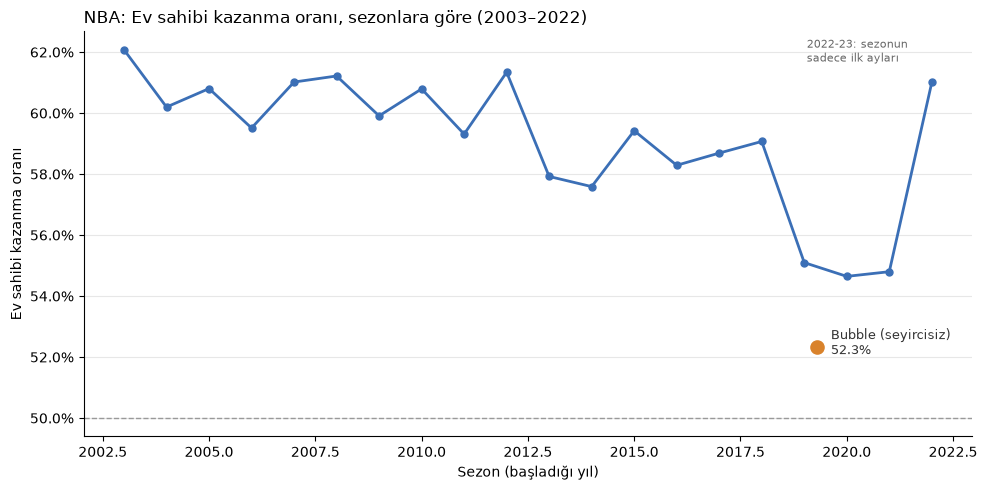

In [5]:
import matplotlib.pyplot as plt

# --- 1) Birebir aynı tekrar eden satırları sil ---
before = len(games)
games = games.drop_duplicates()
print(f"{before - len(games)} duplicate silindi, kalan: {len(games)}")

# --- 2) GAME_ID'den maç türü (ilk hane) ---
type_map = {1: "Preseason", 2: "Regular", 3: "All-Star", 4: "Playoffs", 5: "Play-In"}
games["GAME_TYPE"] = (games["GAME_ID"] // 10_000_000).map(type_map).astype("category")
print(games["GAME_TYPE"].value_counts())

# Hazırlık ve All-Star maçları gerçek rekabet değil -> analizden çıkar
games = games[games["GAME_TYPE"].isin(["Regular", "Playoffs", "Play-In"])].copy()
games["GAME_TYPE"] = games["GAME_TYPE"].cat.remove_unused_categories()

# --- 3) is_bubble (bool, 1 byte) ---
games["is_bubble"] = games["GAME_DATE_EST"].between("2020-07-30", "2020-10-11")
print("Bubble maç sayısı:", games["is_bubble"].sum())

# --- 4) Sezonlara göre ev sahibi kazanma oranı (Bubble maçları hariç) ---
season_rate = (
    games[~games["is_bubble"]]
    .groupby("SEASON")["HOME_TEAM_WINS"]
    .mean()
)
bubble_rate = games.loc[games["is_bubble"], "HOME_TEAM_WINS"].mean()
print(season_rate.round(3))
print(f"Bubble: {bubble_rate:.3f}")

# --- 5) Grafik ---
fig, ax = plt.subplots(figsize=(10, 5))
ax.plot(season_rate.index, season_rate.values, color="#3B6FB6", linewidth=2,
        marker="o", markersize=5)

# Bubble'ı ayrı nokta olarak, 2019 sezonunun yanına koy
ax.scatter(2019.3, bubble_rate, s=90, color="#D9822B", zorder=3)
ax.annotate(f"Bubble (seyircisiz)\n{bubble_rate:.1%}", (2019.3, bubble_rate),
            xytext=(10, -5), textcoords="offset points", fontsize=9, color="#333")

ax.annotate("2022-23: sezonun\nsadece ilk ayları", (2022, season_rate[2022]),
            xytext=(-90, 15), textcoords="offset points", fontsize=8, color="#666")

ax.axhline(0.5, color="#999", linewidth=1, linestyle="--")  # avantaj yok çizgisi
ax.set_title("NBA: Ev sahibi kazanma oranı, sezonlara göre (2003–2022)", loc="left")
ax.set_xlabel("Sezon (başladığı yıl)")
ax.set_ylabel("Ev sahibi kazanma oranı")
ax.yaxis.set_major_formatter(plt.matplotlib.ticker.PercentFormatter(1.0))
ax.grid(axis="y", alpha=0.3)
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.savefig("home_win_rate_by_season.png", dpi=150)
plt.show()

### Bulgu 1: Ev sahibi avantajı 20 yılda eriyor

| Dönem | Ev sahibi kazanma oranı | Seyirci |
|---|---|---|
| 2003–2012 | ~%60–61 | dolu |
| 2013–2018 | ~%58–59 | dolu |
| 2019-20 (Bubble hariç) | %55.1 | dolu (COVID öncesi) |
| **Bubble** | **%52.3** | **yok** |
| 2020-21 | %54.6 | çoğunlukla boş |
| **2021-22** | **%54.8** | **dolu** |

- Düşüş COVID'den **önce** başlamış.
- 2021-22'de seyirci döndü ama avantaj geri **dönmedi**.
- Bubble'ın %52.3'ü düşük görünüyor ama 172 maç az: güven aralığı ≈ ±7.5 puan.

→ Soru "seyirci gitti, avantaj gitti mi?" değil, **"ev sahibi avantajı neden eridi ve seyirci bunun ne kadarını açıklıyor?"**

## 5. Sayı farkı (margin) ve %95 güven aralıkları

Kazanma oranı kaba bir metrik: 1 sayı farkla kazanmak ile 30 sayı farkla kazanmak aynı sayılıyor. **Ev sahibi sayı farkı (`HOME_MARGIN`)** daha hassas, özellikle küçük örneklemde (Bubble).

*Confidence interval* (güven aralığı): iki dönemin aralıkları üst üste biniyorsa aralarında "fark var" diyemeyiz.
- Kazanma oranı için: `1.96 · √(p(1−p)/n)`
- Ortalama sayı farkı için: `1.96 · std / √n`

In [6]:
import numpy as np

# --- 1) Aynı GAME_ID'ye sahip ama içeriği farklı satırlar ---
dup_ids = games[games["GAME_ID"].duplicated(keep=False)].sort_values("GAME_ID")
print(dup_ids[["GAME_ID", "GAME_DATE_EST", "PTS_home", "PTS_away", "GAME_TYPE"]])

# --- 2) Ev sahibi sayı farkı ---
games["HOME_MARGIN"] = (games["PTS_home"] - games["PTS_away"]).astype("Int16")

# --- 3) Dönem bazlı özet + %95 güven aralığı ---
def period(row):
    if row["is_bubble"]:
        return "Bubble"
    return str(row["SEASON"])

games["PERIOD"] = games.apply(period, axis=1)

summary = games.groupby("PERIOD").agg(
    n=("HOME_TEAM_WINS", "size"),
    win_rate=("HOME_TEAM_WINS", "mean"),
    margin=("HOME_MARGIN", "mean"),
    margin_std=("HOME_MARGIN", "std"),
)
summary["win_ci"] = 1.96 * np.sqrt(summary["win_rate"] * (1 - summary["win_rate"]) / summary["n"])
summary["margin_ci"] = 1.96 * summary["margin_std"] / np.sqrt(summary["n"])
print(summary.round(3))

       GAME_ID GAME_DATE_EST  PTS_home  PTS_away GAME_TYPE
2477  22000070    2021-01-01        96        93   Regular
3102  22000070    2021-01-01        96        93   Regular
2483  22000076    2021-01-01       103       106   Regular
3104  22000076    2021-01-01       103       106   Regular
           n  win_rate  margin  margin_std  win_ci  margin_ci
PERIOD                                                       
2003    1271     0.621   3.792      12.011   0.027       0.66
2004    1314     0.602   3.194       12.33   0.026      0.667
2005    1319     0.608   3.462      12.361   0.026      0.667
2006    1309     0.595   3.096      12.718   0.027      0.689
2007    1316     0.610   3.711       13.63   0.026      0.736
2008    1315     0.612   3.306      13.224   0.026      0.715
2009    1312     0.599   2.842      13.272   0.027      0.718
2010    1311     0.608   3.197      12.574   0.026      0.681
2011    1074     0.593   2.966      13.303   0.029      0.796
2012    1314     0.613 

### Bulgu 2: Sayı farkı daha net bir tablo veriyor

- **2003–2012:** ev sahibi maç başına ≈ **+3.3 sayı**
- **2020-21 (çoğunlukla seyircisiz):** **+1.17 ± 0.87** → geçmişe göre anlamlı düşüş (aralıklar örtüşmüyor)
- **2021-22 (seyirci döndü):** **+1.89 ± 0.83** → hafif toparlanma, ama 2020-21'den anlamlı farklı değil
- **Bubble:** **+1.35 ± 2.0** → aralık sıfırı içeriyor; Bubble'da avantaj olduğunu bile söyleyemiyoruz

**Ek gözlem:** `margin_std` (sayı farkının standart sapması) 12'den 15'e çıkmış: maç sonuçları giderek daha değişken (muhtemelen 3 sayı atışlarının artışıyla ilgili).

*Not: Bu hücre, sonraki hücredeki son duplicate temizliğinden önce çalıştırıldı (2 fazla satır); sonuçlara etkisi ihmal edilebilir. Son sürümde temizlik bu hücreden önce yapılmalı.*

## 6. Aynı ID, farklı içerik: 2 maç

Kalan 2 tekrar (`22000070`, `22000076`, ikisi de 1 Ocak 2021) birebir aynı değil:
- `22000070`: sadece `REB_away` farklı (45 / 44)
- `22000076`: sadece `FG_PCT_home` farklı (0.459 / 0.453)

Bunlar maç sonrası yapılan **istatistik düzeltmeleri**; kaynak iki sürümü de kaydetmiş. Skor ve kazanan aynı olduğu için `keep="first"` ile ilk kayıt tutuldu; analize etkisi yok. **Kalan duplicate: 0** (veri kalite kontrolü).

In [7]:
print(dup_ids.loc[:, dup_ids.nunique(dropna=False) > 1])  # sadece farklı olan sütunları göster
games = games.drop_duplicates(subset="GAME_ID", keep="first")
print("Kalan duplicate:", games["GAME_ID"].duplicated().sum())  # 0 olmalı

       GAME_ID  HOME_TEAM_ID  VISITOR_TEAM_ID  TEAM_ID_home  PTS_home  \
2477  22000070    1610612765       1610612738    1610612765        96   
3102  22000070    1610612765       1610612738    1610612765        96   
2483  22000076    1610612743       1610612756    1610612743       103   
3104  22000076    1610612743       1610612756    1610612743       103   

      FG_PCT_home  FT_PCT_home  FG3_PCT_home  AST_home  REB_home  \
2477        0.409        0.650         0.324        18        48   
3102        0.409        0.650         0.324        18        48   
2483        0.459        0.813         0.414        28        38   
3104        0.453        0.813         0.414        28        38   

      TEAM_ID_away  PTS_away  FG_PCT_away  FT_PCT_away  FG3_PCT_away  \
2477    1610612738        93        0.470        0.500         0.258   
3102    1610612738        93        0.470        0.500         0.258   
2483    1610612756       106        0.487        0.905         0.371   
3104 

## 7. Hipotez testi: 2019-20'deki düşüş COVID'le mi ilgili?

**Hipotez:** 2019-20 sezonunun (Bubble hariç) düşük ev sahibi oranı COVID'in başlangıcıyla ilgili. Doğruysa düşüş sezon sonuna (Mart 2020) yoğunlaşmalı.

**Karşılaştırma:** 2019-20'nin her ayı, 2015–2018 sezonlarının aynı ayıyla.

In [8]:
games["MONTH"] = games["GAME_DATE_EST"].dt.month

# 2019-20 sezonu, Bubble hariç (hepsi seyircili maçlar)
s2019 = games[(games["SEASON"] == 2019) & (~games["is_bubble"])]

# Karşılaştırma: 2015-2018 sezonları (normal dönem), normal sezon maçları
base = games[games["SEASON"].between(2015, 2018) & (games["GAME_TYPE"] == "Regular")]

month_order = [10, 11, 12, 1, 2, 3]
compare = pd.DataFrame({
    "2019_win":   s2019.groupby("MONTH")["HOME_TEAM_WINS"].mean(),
    "2019_n":     s2019.groupby("MONTH").size(),
    "2015_18_win": base.groupby("MONTH")["HOME_TEAM_WINS"].mean(),
}).reindex(month_order)

print(compare.round(3))

       2019_win  2019_n  2015_18_win
MONTH                               
10        0.603    68.0        0.572
11        0.600   215.0        0.587
12        0.532   220.0        0.599
1         0.505   222.0        0.591
2         0.595   168.0        0.546
3         0.462    78.0        0.604


### Bulgu 3: Hipotez kısmen destekleniyor, ama ikna edici değil

| Ay | 2019-20 | 2015–18 ort. | Yorum |
|---|---|---|---|
| Ekim–Kasım | %60 | %57–59 | normal |
| **Aralık–Ocak** | **%53 / %50.5** | %59–60 | **COVID öncesi düşüş** |
| Şubat | %59.5 | %54.6 | toparlanma |
| **Mart (1–11)** | **%46** | %60 | düşük, ama sadece 78 maç (±11 puan) |

- Mart'taki düşüş hipotezle uyumlu, ancak Aralık–Ocak düşüşü COVID'den önce ve Mart örneklemi çok küçük.
- 2015–18 ortalaması bile aydan aya %54.6–60.4 arasında oynuyor: aylık veri gürültülü. 6 ay ayrı ayrı test edildiğinde bazıları şans eseri farklı görünebilir (*multiple comparisons problem*).

**Sonuç:** "COVID 2019-20 düşüşünü açıklıyor" diyemeyiz.

## 8. Feature engineering (model için)

**Kritik tuzak – data leakage (veri sızıntısı):** `PTS`, `FG_PCT`, `REB` gibi sütunlar maç *bittikten sonra* bilinir. Bunlarla kazananı tahmin etmek hile olur (bu veri setiyle yapılan birçok Kaggle notebook'u %90+ doğruluğu böyle elde ediyor). **Modelimiz sadece maç öncesinde bilinen bilgileri kullanıyor.**

**Özellikler:**
- `WIN_L10`, `MARGIN_L10`: takımın son 10 maçtaki kazanma oranı ve ortalama sayı farkı (form). `shift(1)` ile o maçın kendisi hesaba katılmıyor.
- `REST`: önceki maçtan bu yana geçen gün (7'de kırpıldı; sezonun ilk maçı = 7)
- `DIFF_*`: ev sahibi − deplasman farkları
- `no_crowd`: Bubble **veya** 2020-21 sezonu

**Teknik:** Takım formunu hesaplamak için tablo *long format*'a (her maç iki satır: ev sahibi ve deplasman bakış açısı) çevrildi, `groupby(["TEAM_ID", "SEASON"]).transform(...)` ile hesaplanıp geri birleştirildi.

**Varsayım:** 2020-21 sezonunun sonlarında bazı salonlar sınırlı seyirci aldı; `no_crowd` bu yüzden yaklaşık bir bayrak.

In [9]:
# --- 1) Long format: her maç iki satır (ev sahibi ve deplasman perspektifi) ---
home = pd.DataFrame({
    "GAME_ID": games["GAME_ID"], "DATE": games["GAME_DATE_EST"], "SEASON": games["SEASON"],
    "TEAM_ID": games["HOME_TEAM_ID"],
    "WIN": games["HOME_TEAM_WINS"].astype(float),
    "MARGIN": games["HOME_MARGIN"].astype(float),
})
away = pd.DataFrame({
    "GAME_ID": games["GAME_ID"], "DATE": games["GAME_DATE_EST"], "SEASON": games["SEASON"],
    "TEAM_ID": games["VISITOR_TEAM_ID"],
    "WIN": (~games["HOME_TEAM_WINS"]).astype(float),
    "MARGIN": -games["HOME_MARGIN"].astype(float),
})
long = pd.concat([home, away]).sort_values(["TEAM_ID", "DATE"])

# --- 2) Maç ÖNCESİ form: shift(1) ile o maçın kendisini dışarıda bırak ---
g = long.groupby(["TEAM_ID", "SEASON"])
long["WIN_L10"] = g["WIN"].transform(lambda s: s.shift(1).rolling(10, min_periods=3).mean())
long["MARGIN_L10"] = g["MARGIN"].transform(lambda s: s.shift(1).rolling(10, min_periods=3).mean())
long["REST"] = g["DATE"].diff().dt.days.clip(upper=7).fillna(7)

# --- 3) Özellikleri maç tablosuna geri bağla (ev sahibi ve deplasman ayrı) ---
feat = long[["GAME_ID", "TEAM_ID", "WIN_L10", "MARGIN_L10", "REST"]]
games = (
    games
    .merge(feat.rename(columns={"TEAM_ID": "HOME_TEAM_ID", "WIN_L10": "WIN_L10_H",
                                "MARGIN_L10": "MARGIN_L10_H", "REST": "REST_H"}),
           on=["GAME_ID", "HOME_TEAM_ID"], how="left")
    .merge(feat.rename(columns={"TEAM_ID": "VISITOR_TEAM_ID", "WIN_L10": "WIN_L10_A",
                                "MARGIN_L10": "MARGIN_L10_A", "REST": "REST_A"}),
           on=["GAME_ID", "VISITOR_TEAM_ID"], how="left")
)

# --- 4) Fark özellikleri + seyircisiz dönem ---
games["DIFF_WIN_L10"] = games["WIN_L10_H"] - games["WIN_L10_A"]
games["DIFF_MARGIN_L10"] = games["MARGIN_L10_H"] - games["MARGIN_L10_A"]
games["DIFF_REST"] = games["REST_H"] - games["REST_A"]
games["no_crowd"] = games["is_bubble"] | (games["SEASON"] == 2020)

model_df = games.dropna(subset=["DIFF_WIN_L10", "DIFF_MARGIN_L10"])
print(len(games), "->", len(model_df), "satır (sezon başı ilk maçlar düştü)")
print(model_df[["DIFF_WIN_L10", "DIFF_MARGIN_L10", "DIFF_REST", "no_crowd"]].describe())

24848 -> 23888 satır (sezon başı ilk maçlar düştü)
       DIFF_WIN_L10  DIFF_MARGIN_L10     DIFF_REST
count  23888.000000     23888.000000  23888.000000
mean      -0.005269        -0.168723      0.227520
std        0.299755         8.732176      1.059862
min       -1.000000       -32.400000     -6.000000
25%       -0.200000        -6.100000      0.000000
50%        0.000000        -0.200000      0.000000
75%        0.200000         5.800000      1.000000
max        1.000000        43.166667      6.000000


### Model verisi hazır

- 24.848 maç → **23.888 satır** (her takımın sezon başındaki ilk maçlarında form hesaplanamadığı için düştü).
- `DIFF_REST` ortalaması **+0.23**: ev sahipleri ortalamada deplasmana göre biraz daha dinlenmiş geliyor; fikstür kaynaklı küçük bir avantaj olabilir.

**Sonraki adım:** Logistic Regression, zamana göre bölünmüş eğitim/test (temporal split). Baseline: "her zaman ev sahibi kazanır" tahmini (~%58). Ana soru: takım gücü kontrol edildiğinde `no_crowd` katsayısı ne söylüyor?

## 9. Model: Neden özellik çıkarıp modele geçiyoruz?

EDA **ne olduğunu** gösterdi: seyircisiz dönemlerde ev sahibi daha az kazanıyor. Ama **neden** olduğunu ayıramıyor, çünkü işin içinde *confounder*'lar (karıştırıcı değişkenler) var:

1. **Bubble'daki playoff maçları:** Playoff'ta "ev sahibi" sıralamada üstteki takım, yani çoğu zaman zaten daha güçlü takım. Bubble'daki %52.3'ün bir kısmı seyirciden değil, takım gücünden geliyor olabilir.
2. **20 yıllık düşüş trendi:** Ev sahibi avantajı COVID'den önce de eriyordu. Seyircisiz dönemler bu trendin sonuna denk geliyor; basit ortalama, trendin etkisi ile seyircinin etkisini ayıramaz.

Model ile şu soruyu sorabiliyoruz: *"Takım formu, dinlenme, maç türü ve yıl sabitken, seyircinin olmaması ev sahibinin kazanma ihtimalini ne kadar değiştiriyor?"* Diğer değişkenleri sabit tutmaya **kontrol etmek** denir.

### Modeli iki amaçla kullanıyoruz

| | A) Tahmin (prediction) | B) Açıklama (inference) |
|---|---|---|
| Soru | Maç sonucunu ne kadar iyi tahmin edebiliriz? | Seyircinin etkisi ne kadar? |
| Veri | Train: 2003–2016, Test: 2017–2022 (temporal split) | Tüm veri |
| Araç | scikit-learn (`Pipeline` + `LogisticRegression`) | statsmodels (`logit`) |
| Metrik | Accuracy, AUC, log loss, baseline'a göre | `no_crowd` katsayısı ve güven aralığı |

- **Baseline:** "Her zaman ev sahibi kazanır" tahmini. Model bunu geçemezse, form bilgisi bir değer katmıyor demektir.
- **`no_crowd` A modelinde yok:** Seyircisiz maçlar sadece 2019–2020'de var. Eğitim verisinde bulunmadığı için model ondan bir şey öğrenemez.
- **Ek kontroller (B):** `PLAYOFF` (playoff'ta ev sahibi = üst sıradaki takım) ve `TREND` (sezon − 2003, uzun vadeli düşüş).
- **`StandardScaler`** pipeline içinde kullanılıyor: sadece eğitim verisinden öğreniliyor, böylece test verisi eğitime sızmıyor (leakage önleniyor).

### Metrikler
- **Accuracy:** Doğru tahmin oranı.
- **AUC:** Kazananı kaybedenden ayırma gücü. 0.5 yazı-tura, 1.0 mükemmel ayrım.
- **Log loss:** Olasılık tahminlerinin kalitesi. Yüksek güvenle yapılan yanlış tahmin ağır cezalandırılır.
- **Katsayı yorumu:** `no_crowd` katsayısı negatifse ve %95 güven aralığı (`[0.025, 0.975]`) sıfırı içermiyorsa, takım gücü ve trend kontrol edildikten sonra bile seyircisizlik ev sahibi avantajını azaltıyor demektir. Katsayı, eşit güçte iki takım için kazanma olasılığına çevrilerek yorumlanıyor.


In [10]:
import numpy as np
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, roc_auc_score, log_loss
import statsmodels.formula.api as smf

df = model_df.copy()
df["HOME_WIN"] = df["HOME_TEAM_WINS"].astype(int)
df["no_crowd"] = df["no_crowd"].astype(int)
df["PLAYOFF"] = (df["GAME_TYPE"] != "Regular").astype(int)  # playoff/play-in: "ev sahibi" = üst sıradaki takım
df["TREND"] = df["SEASON"] - 2003                             # 20 yıllık düşüş trendi

# ================= A) TAHMİN: zamana göre bölme =================
feats = ["DIFF_WIN_L10", "DIFF_MARGIN_L10", "DIFF_REST", "PLAYOFF"]
train = df[df["SEASON"] <= 2016]
test = df[df["SEASON"] >= 2017]

clf = make_pipeline(StandardScaler(), LogisticRegression())
clf.fit(train[feats], train["HOME_WIN"])
proba = clf.predict_proba(test[feats])[:, 1]

baseline_acc = test["HOME_WIN"].mean()  # "her zaman ev sahibi kazanır" tahmininin doğruluğu
print(f"Train: {len(train)} maç (2003-2016) | Test: {len(test)} maç (2017-2022)")
print(f"Baseline accuracy : {baseline_acc:.3f}")
print(f"Model accuracy    : {accuracy_score(test['HOME_WIN'], proba > 0.5):.3f}")
print(f"Model AUC         : {roc_auc_score(test['HOME_WIN'], proba):.3f}")
print(f"Model log loss    : {log_loss(test['HOME_WIN'], proba):.3f}")

# ================= B) AÇIKLAMA: seyircinin etkisi =================
logit = smf.logit(
    "HOME_WIN ~ DIFF_WIN_L10 + DIFF_MARGIN_L10 + DIFF_REST + PLAYOFF + TREND + no_crowd",
    data=df,
).fit(disp=False)
print(logit.summary().tables[1])

# Katsayıyı olasılığa çevir: eşit güçte iki takım, 2020 yılı, normal sezon maçı
p = logit.params
def home_prob(no_crowd, season=2020):
    z = p["Intercept"] + p["TREND"] * (season - 2003) + p["no_crowd"] * no_crowd
    return 1 / (1 + np.exp(-z))

print(f"\nEşit güçte takımlar, 2020 sezonu:")
print(f"  Seyirciyle    : ev sahibi kazanma ihtimali {home_prob(0):.1%}")
print(f"  Seyircisiz    : ev sahibi kazanma ihtimali {home_prob(1):.1%}")

Train: 17436 maç (2003-2016) | Test: 6452 maç (2017-2022)
Baseline accuracy : 0.568
Model accuracy    : 0.619
Model AUC         : 0.659
Model log loss    : 0.648
                      coef    std err          z      P>|z|      [0.025      0.975]
-----------------------------------------------------------------------------------
Intercept           0.4928      0.028     17.891      0.000       0.439       0.547
DIFF_WIN_L10        0.4756      0.097      4.907      0.000       0.286       0.666
DIFF_MARGIN_L10     0.0612      0.003     18.060      0.000       0.055       0.068
DIFF_REST           0.0651      0.013      4.949      0.000       0.039       0.091
PLAYOFF             0.2341      0.056      4.204      0.000       0.125       0.343
TREND              -0.0107      0.003     -4.061      0.000      -0.016      -0.006
no_crowd           -0.1343      0.064     -2.099      0.036      -0.260      -0.009

Eşit güçte takımlar, 2020 sezonu:
  Seyirciyle    : ev sahibi kazanma ihtimali 57

### Bulgu 4: Model sonuçları

**A) Tahmin (Train: 2003–2016, 17.436 maç | Test: 2017–2022, 6.452 maç)**

| | Accuracy | AUC | Log loss |
|---|---|---|---|
| Baseline (her zaman ev sahibi) | 0.568 | 0.500 | 0.684 |
| Logistic Regression | **0.619** | **0.659** | **0.648** |

- Model, baseline'ı **5.1 puan** geçiyor. Sadece maç öncesi form ve dinlenme bilgisiyle, sızıntı (leakage) olmadan elde edildi.
- %62 mütevazı bir oran. Ama bu, maç istatistikleri kullanılarak raporlanan %90+ sonuçlardan farklı olarak **gerçekten maçtan önce yapılabilecek** bir tahmin.

**B) Seyircinin etkisi (tüm veri, statsmodels Logit)**

| Değişken | Katsayı | 95% CI | Yorum |
|---|---|---|---|
| `no_crowd` | **−0.134** | [−0.260, −0.009] | Seyircisizlik ev sahibi avantajını azaltıyor (p = 0.036) |
| `TREND` | −0.011 / yıl | [−0.016, −0.006] | Uzun vadeli düşüş, seyirciden bağımsız |
| `PLAYOFF` | +0.234 | [0.125, 0.343] | Playoff'ta "ev sahibi" (üst sıradaki takım) formdan bağımsız olarak daha avantajlı → confounder doğrulandı |
| `DIFF_REST` | +0.065 | [0.039, 0.091] | Her ekstra dinlenme günü farkı ev sahibine yarıyor |

**Olasılığa çevrilmiş hâli (eşit güçte takımlar, 2020 sezonu, normal sezon maçı):**
- Seyirciyle: **%57.7**
- Seyircisiz: **%54.4** → seyirci etkisi ≈ **3.3 puan**

**Yorum:**
- Takım gücü, dinlenme, maç türü ve uzun vadeli trend kontrol edildikten sonra bile **seyircisizlik ev sahibi avantajını anlamlı biçimde azaltıyor.**
- Ama etki sınırda: güven aralığının üst ucu (−0.009) sıfıra çok yakın. "Seyirci etkisi var" diyebiliriz, büyüklüğü ise belirsiz.
- **Seyirci, avantajın sadece bir kısmını açıklıyor.** Eşit takımlar için ev sahibi oranı 2003'te ≈ %62 iken, sadece trend 20 yılda ≈ 5 puan düşürmüş. Seyircisizliğin etkisi ise ≈ 3 puan. Yani ev sahibi avantajını eriten başka faktörler de var (seyahat koşulları, analitik, oyun stili vb.; bu veriyle test edilemez).

**Sınırlamalar:**
- `no_crowd` yaklaşık bir bayrak: 2020-21 sonunda bazı salonlar sınırlı seyirci aldı.
- Bu bir gözlemsel çalışma; bulgular nedensellik değil, kontrol edilmiş ilişki gösteriyor.
- `DIFF_WIN_L10` ve `DIFF_MARGIN_L10` birbiriyle ilişkili (*multicollinearity*), bu yüzden bu ikisinin katsayıları tek tek yorumlanmamalı. İkisi de kontrol değişkeni olarak modelde.

## 10. Power BI için dışa aktarma

Analiz sonuçları, Power BI dashboard'unda kullanılmak üzere `powerbi/` klasörüne 4 CSV dosyası olarak kaydediliyor:

| Dosya | İçerik | Dashboard'daki yeri |
|---|---|---|
| `donem_ozeti.csv` | Sezon bazlı kazanma oranı ve sayı farkı, %95 güven aralıklarıyla (Bubble ayrı satır) | Sayfa 1: trend grafikleri, KPI kartları |
| `aylik_2019.csv` | 2019-20 sezonu ile 2015–18 ortalamasının aylık karşılaştırması | Sayfa 2: COVID hipotezi |
| `model_katsayilar.csv` | Logit model katsayıları, güven aralıkları ve p-değerleri | Sayfa 2: seyirci etkisi |
| `maclar.csv` | Temizlenmiş maç bazlı veri | Filtreler ve dinamik ölçüler |

**Format notu:** Dosyalar standart CSV formatında (ayırıcı `,`, ondalık `.`). Power BI'ın bölge ayarı İngilizce olduğu için bu format doğru okunuyor. Türkçe bölge ayarlı bir bilgisayarda açılırsa, Power Query'de tip değiştirirken **"Yerel Ayarı Kullanarak"** seçeneğiyle İngilizce (ABD) seçilmeli.

In [13]:
import os
os.makedirs("powerbi", exist_ok=True)
tr = dict(index=False, encoding="utf-8-sig")  # standart CSV: ayırıcı virgül, ondalık nokta
# --- 1) Dönem özeti (sezonlar + Bubble) ---
crowd = {2019: "Dolu (COVID öncesi)", 2020: "Çoğunlukla boş", 2022: "Dolu (yarım sezon)"}
s = summary.reset_index()
s["SEZON"] = s["PERIOD"].apply(lambda p: p if p == "Bubble" else f"{p}-{str(int(p)+1)[-2:]}")
s["SEYIRCI"] = s["PERIOD"].apply(lambda p: "Yok" if p == "Bubble" else crowd.get(int(p), "Dolu"))
s["SIRA"] = s["PERIOD"].apply(lambda p: 2019.5 if p == "Bubble" else int(p))  # grafikte sıralama
s["WIN_ALT"], s["WIN_UST"] = s["win_rate"] - s["win_ci"], s["win_rate"] + s["win_ci"]
s["MARGIN_ALT"], s["MARGIN_UST"] = s["margin"] - s["margin_ci"], s["margin"] + s["margin_ci"]
s.sort_values("SIRA").to_csv("powerbi/donem_ozeti.csv", **tr)

# --- 2) COVID hipotezi: aylık karşılaştırma ---
ay_adi = {10: "Ekim", 11: "Kasım", 12: "Aralık", 1: "Ocak", 2: "Şubat", 3: "Mart"}
m = compare.reset_index().rename(columns={"index": "MONTH"})
m["AY"] = m["MONTH"].map(ay_adi)
m["SIRA"] = range(1, len(m) + 1)
m.to_csv("powerbi/aylik_2019.csv", **tr)

# --- 3) Model katsayıları (güven aralıklarıyla) ---
ci = logit.conf_int()
coef = pd.DataFrame({
    "DEGISKEN": logit.params.index,
    "KATSAYI": logit.params.values,
    "ALT": ci[0].values, "UST": ci[1].values,
    "P_DEGERI": logit.pvalues.values,
})
coef[coef["DEGISKEN"] != "Intercept"].to_csv("powerbi/model_katsayilar.csv", **tr)

# --- 4) Maç bazlı temiz veri (slicer/filtre için) ---
cols = ["GAME_ID", "GAME_DATE_EST", "SEASON", "GAME_TYPE", "is_bubble",
        "HOME_TEAM_ID", "VISITOR_TEAM_ID", "PTS_home", "PTS_away", "HOME_MARGIN", "HOME_TEAM_WINS"]
g = games[cols].copy()
g["HOME_TEAM_WINS"] = g["HOME_TEAM_WINS"].astype(int)  # Power BI'da ortalaması alınabilsin
g["is_bubble"] = g["is_bubble"].astype(int)
g.to_csv("powerbi/maclar.csv", **tr)

print(os.listdir("powerbi"))

['aylik_2019.csv', 'donem_ozeti.csv', 'maclar.csv', 'model_katsayilar.csv']
